In [2]:
# Loading the trained model and test data
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models")
REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["disease_encoded"]

label_encoder = joblib.load(DATA_DIR / "label_encoder.joblib")
rf_model = joblib.load(MODEL_DIR / "random_forest_model.joblib")

print("Model and test data loaded successfully.")
print("Test shape:", X_test.shape)

Model and test data loaded successfully.
Test shape: (20000, 174)


In [5]:
y_pred = rf_model.predict(X_test)

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Macro F1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Weighted F1": f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
}

for name, score in metrics.items():
    print(f"{name}: {score:.4f}")

Accuracy: 0.3523
Macro F1: 0.2229
Weighted F1: 0.3567


In [6]:
# Saving the metrics
pd.DataFrame([metrics]).to_csv(
    REPORT_DIR / "random_forest_metrics.csv",
    index=False
)

print("Metrics saved.")

Metrics saved.


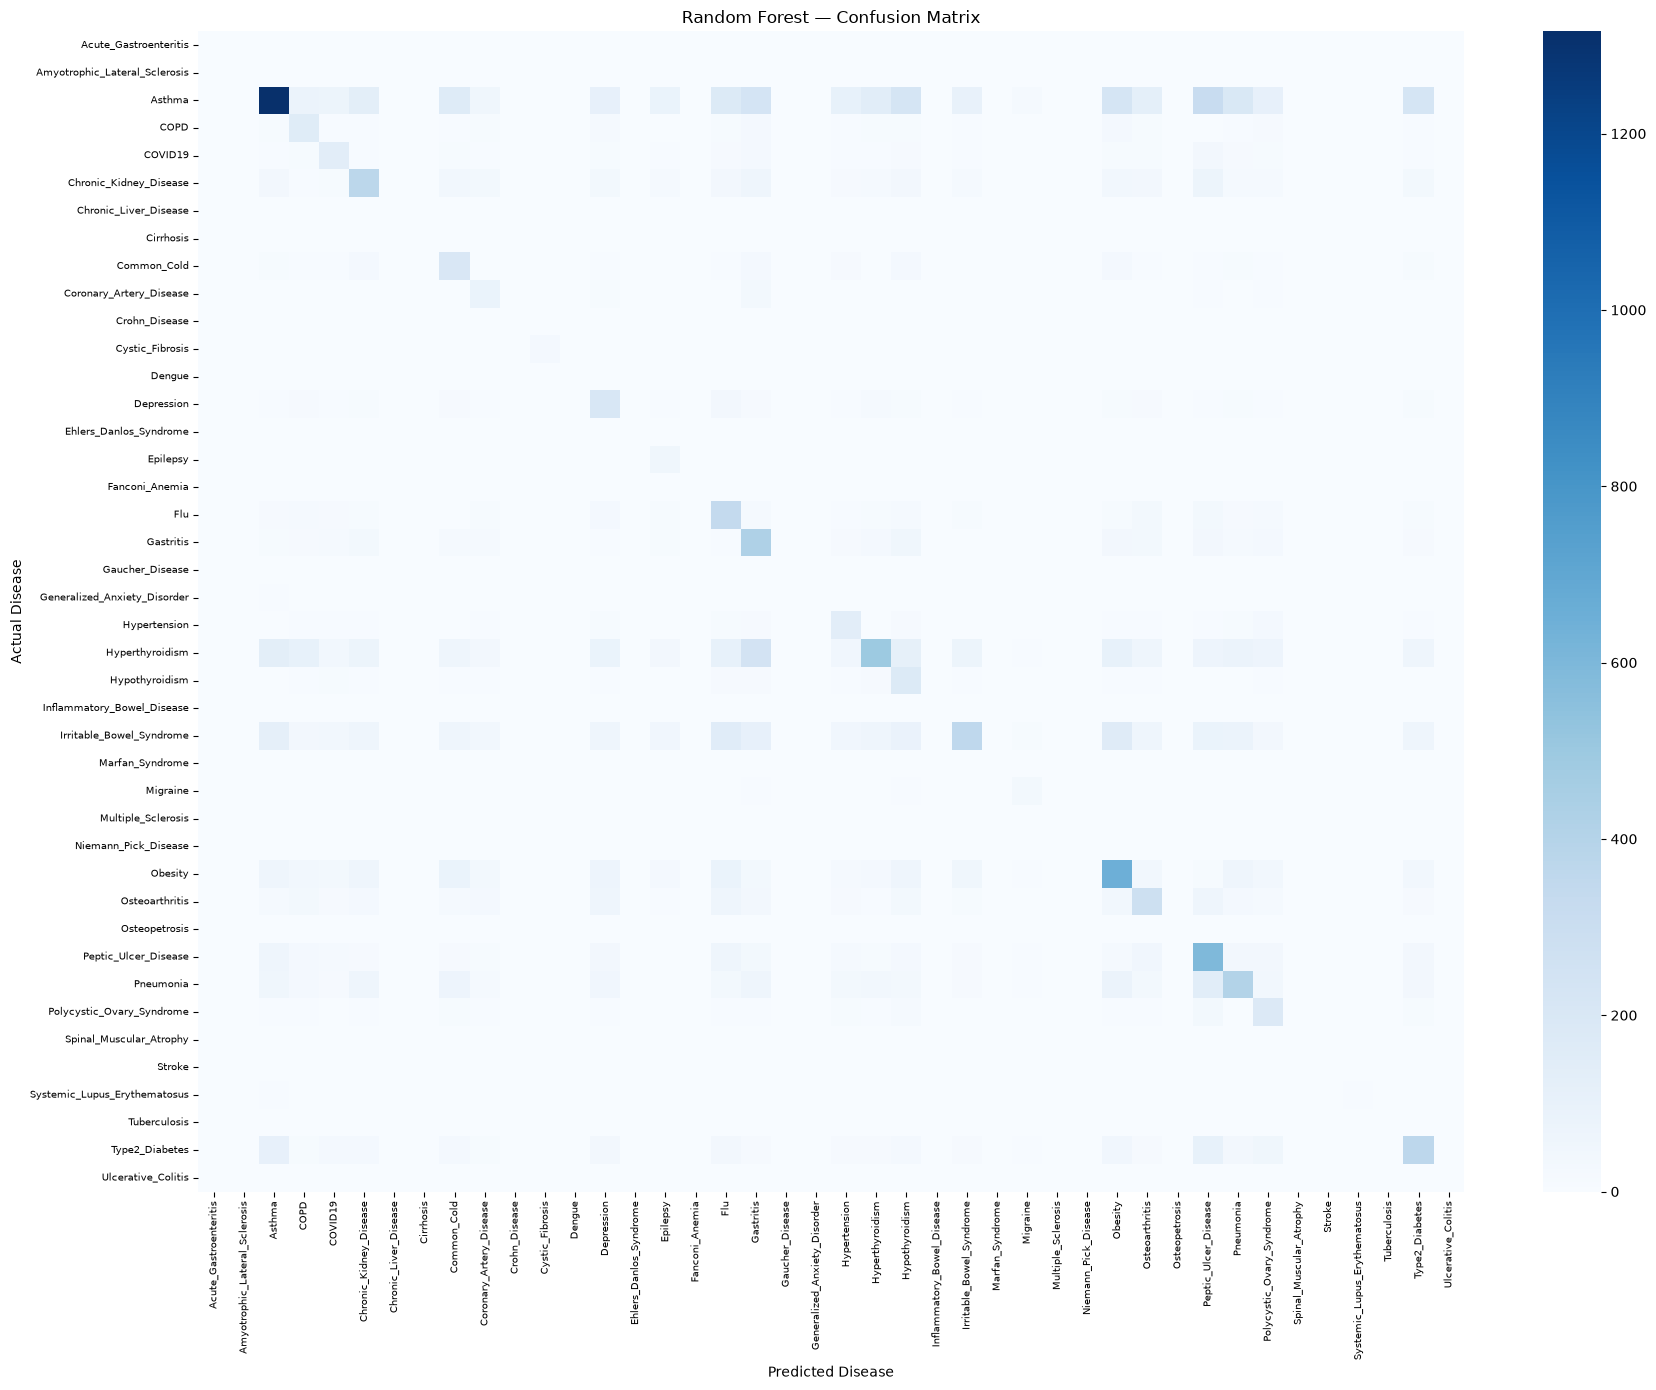

In [8]:
# Plotting of Confusion Matrix
class_ids = np.unique(y_test)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=class_ids
)

class_names = label_encoder.inverse_transform(class_ids)

plt.figure(figsize=(18, 14))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "random_forest_confusion_matrix.png",
    dpi=200
)

plt.show()

Top 20 influential symptoms:
rare_symptom_developmental_delay_rare          0.011993
rare_symptom_hyperextensible_skin_rare         0.010077
rare_symptom_respiratory_failure_rare          0.010032
rare_symptom_bone_fractures_pathologic_rare    0.009841
symptom_reduced_range_of_motion                0.009809
symptom_insomnia                               0.009526
rare_symptom_digital_clubbing                  0.009253
symptom_photosensitivity_symptom               0.009074
symptom_easy_bruising                          0.009014
symptom_photophobia                            0.008757
symptom_cold_intolerance_symptom               0.008614
rare_symptom_lens_dislocation_rare             0.008453
symptom_cyanosis                               0.008227
symptom_weight_gain_symptom                    0.008004
symptom_hypopigmentation                       0.007921
symptom_lymph_node_swelling                    0.007909
symptom_chills                                 0.007905
symptom_suicidal_id

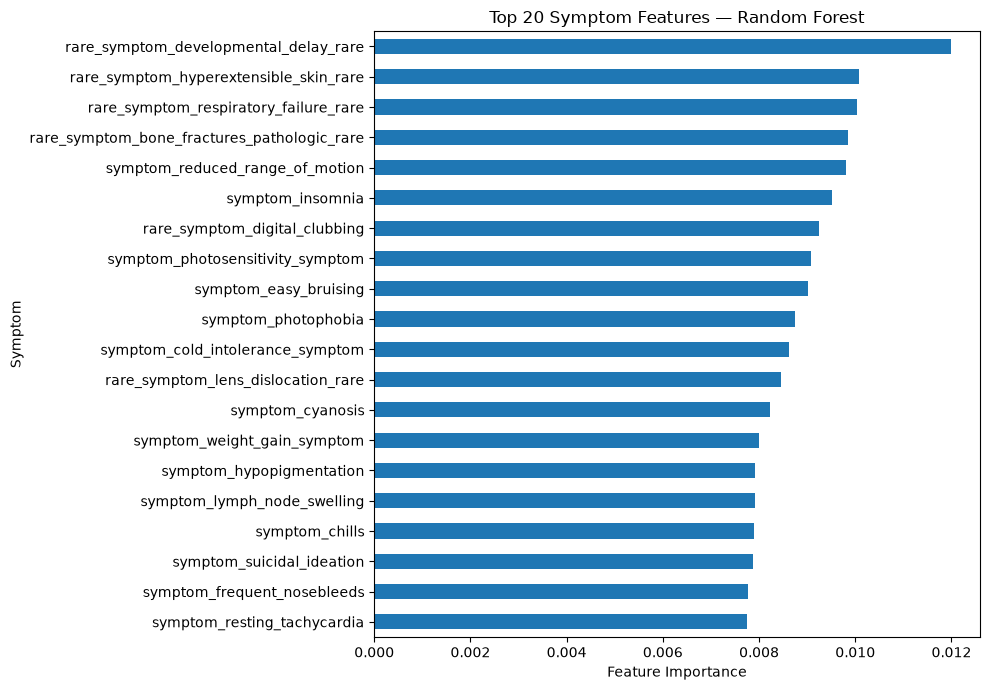

In [9]:
# Identifying the mosst influential symptoms
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_test.columns
).sort_values(ascending=False)

print("Top 20 influential symptoms:")
print(importance.head(20))

plt.figure(figsize=(10, 7))

importance.head(20).sort_values().plot(kind="barh")

plt.title("Top 20 Symptom Features — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Symptom")
plt.tight_layout()

plt.savefig(
    REPORT_DIR / "random_forest_feature_importance.png",
    dpi=200
)

plt.show()